<a href="https://colab.research.google.com/github/ecesariarslan/BAS120-Dunnhumby-Customer-Analytics/blob/main/BAS120_Dunnhumby_Project_Ece.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [9]:
db_path = "/content/dunnhumby.duckdb"

con = duckdb.connect(db_path, read_only=True)

con.execute("SHOW TABLES").df()

,name
0,campaign_desc_adj
1,campaign_table
2,coupon
3,coupon_redempt_adj
4,hh_demographic
5,product
6,transaction_data
7,week_start_end


In [10]:
con.execute("DESCRIBE transaction_data").df()

,column_name,column_type,null,key,default,extra
0,household_key,BIGINT,YES,None,None,None
1,BASKET_ID,BIGINT,YES,None,None,None
2,PRODUCT_ID,BIGINT,YES,None,None,None
3,QUANTITY,BIGINT,YES,None,None,None
4,SALES_VALUE,DOUBLE,YES,None,None,None
5,STORE_ID,BIGINT,YES,None,None,None
6,RETAIL_DISC,DOUBLE,YES,None,None,None
7,COUPON_DISC,DOUBLE,YES,None,None,None
8,COUPON_MATCH_DISC,DOUBLE,YES,None,None,None
9,WEEK_NO,BIGINT,YES,None,None,None


In [11]:
con.execute("""
SELECT *
FROM transaction_data
LIMIT 5
""").df()

,household_key,BASKET_ID,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC,WEEK_NO,Trans_Datetime
0,2375,26984851472,1004906,1,1.39,364,-0.60,0.0,0.0,1,2016-03-23 16:31:00
1,2375,26984851472,1033142,1,0.82,364,0.00,0.0,0.0,1,2016-03-23 16:31:00
2,2375,26984851472,1036325,1,0.99,364,-0.30,0.0,0.0,1,2016-03-23 16:31:00
3,2375,26984851472,1082185,1,1.21,364,0.00,0.0,0.0,1,2016-03-23 16:31:00
4,2375,26984851472,8160430,1,1.50,364,-0.39,0.0,0.0,1,2016-03-23 16:31:00


In [12]:
con.execute("""
SELECT
    MIN(Trans_Datetime) AS earliest_transaction,
    MAX(Trans_Datetime) AS latest_transaction,
    MIN(WEEK_NO) AS first_week,
    MAX(WEEK_NO) AS last_week
FROM transaction_data
""").df()

,earliest_transaction,latest_transaction,first_week,last_week
0,2016-03-23 09:46:00,2017-12-31 23:01:00,1,93


In [13]:
weekly_summary = con.execute("""
SELECT
    WEEK_NO,
    COUNT(*) AS transaction_rows,
    COUNT(DISTINCT BASKET_ID) AS baskets,
    COUNT(DISTINCT household_key) AS active_households,
    ROUND(SUM(SALES_VALUE), 2) AS total_sales
FROM transaction_data
GROUP BY WEEK_NO
ORDER BY WEEK_NO
""").df()

weekly_summary

,WEEK_NO,transaction_rows,baskets,active_households,total_sales
0,1,1881,142,88,5211.16
1,2,3675,324,175,10821.35
2,3,4803,482,228,13498.20
3,4,5379,545,270,15965.99
4,5,7168,757,370,20139.82
...,...,...,...,...,...
88,89,28734,2893,1328,90544.76
89,90,29268,2915,1356,92939.24
90,91,26973,2933,1342,86923.35
91,92,33126,3362,1428,113192.87


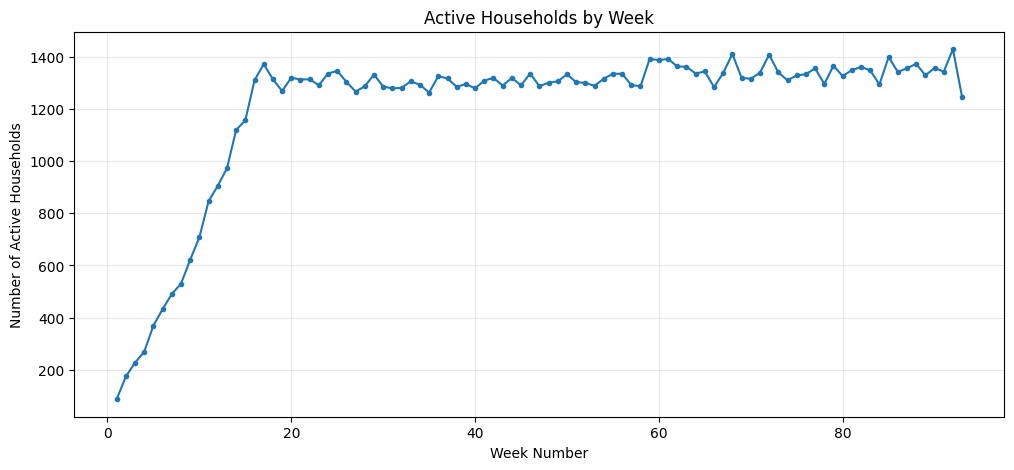

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_summary["WEEK_NO"],
    weekly_summary["active_households"],
    marker="o",
    markersize=3
)

plt.title("Active Households by Week")
plt.xlabel("Week Number")
plt.ylabel("Number of Active Households")
plt.grid(True, alpha=0.3)

plt.show()

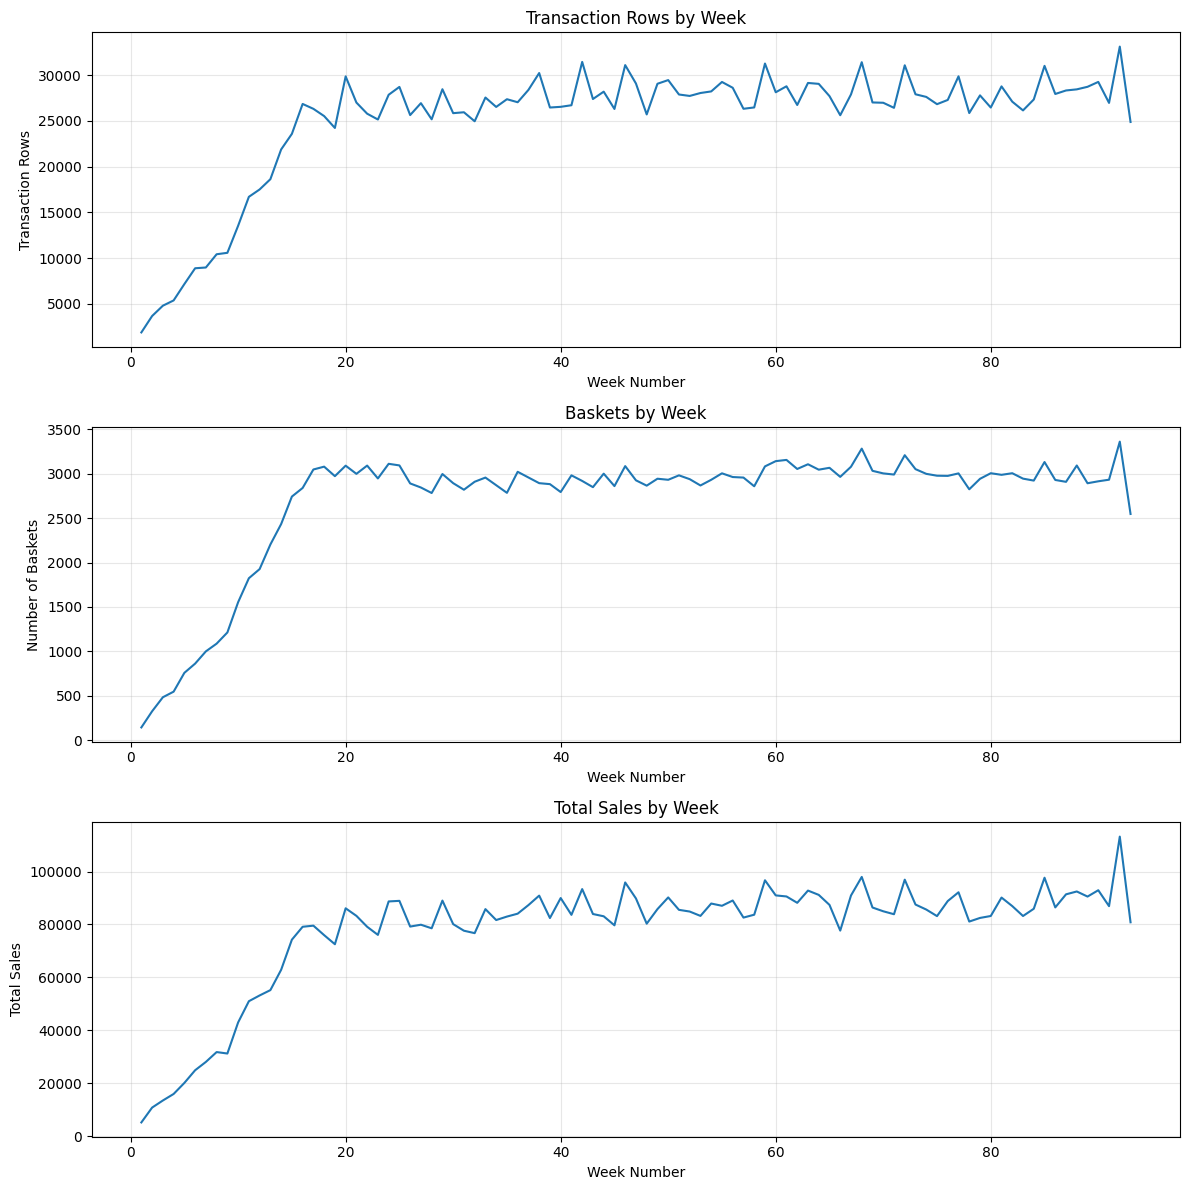

In [15]:
fig, ax = plt.subplots(3, 1, figsize=(12, 12))

ax[0].plot(
    weekly_summary["WEEK_NO"],
    weekly_summary["transaction_rows"]
)
ax[0].set_title("Transaction Rows by Week")
ax[0].set_xlabel("Week Number")
ax[0].set_ylabel("Transaction Rows")
ax[0].grid(True, alpha=0.3)

ax[1].plot(
    weekly_summary["WEEK_NO"],
    weekly_summary["baskets"]
)
ax[1].set_title("Baskets by Week")
ax[1].set_xlabel("Week Number")
ax[1].set_ylabel("Number of Baskets")
ax[1].grid(True, alpha=0.3)

ax[2].plot(
    weekly_summary["WEEK_NO"],
    weekly_summary["total_sales"]
)
ax[2].set_title("Total Sales by Week")
ax[2].set_xlabel("Week Number")
ax[2].set_ylabel("Total Sales")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Decision Record 1 — Trustworthy Time Window
Evidence: The weekly summaries showed that active households, transaction rows, baskets, and total sales increased sharply during the first 17 weeks. Beginning around Week 18, these measures became much more stable.
Decision: I will exclude Weeks 1–17 and use Week 18 as the beginning of the reliable analysis period.
Logic: The early weeks appear to represent a ramp-up period and may not be comparable with the more stable later weeks.
Alternative and tradeoff: Using all 93 weeks would provide more data, but the unusually low activity in the early weeks could distort customer behavior patterns.Week 93 showed lower activity than Week 92, but it still contained seven active days, so I kept it in the analysis

In [16]:
con.execute("""
SELECT
    WEEK_NO,
    MIN(Trans_Datetime) AS first_transaction,
    MAX(Trans_Datetime) AS last_transaction,
    COUNT(DISTINCT CAST(Trans_Datetime AS DATE)) AS active_days,
    COUNT(*) AS transaction_rows,
    COUNT(DISTINCT BASKET_ID) AS baskets,
    COUNT(DISTINCT household_key) AS active_households,
    ROUND(SUM(SALES_VALUE), 2) AS total_sales
FROM transaction_data
WHERE WEEK_NO >= 89
GROUP BY WEEK_NO
ORDER BY WEEK_NO
""").df()

,WEEK_NO,first_transaction,last_transaction,active_days,transaction_rows,baskets,active_households,total_sales
0,89,2017-11-27 00:08:00,2017-12-03 23:52:00,7,28734,2893,1328,90544.76
1,90,2017-12-04 00:10:00,2017-12-10 23:18:00,7,29268,2915,1356,92939.24
2,91,2017-12-11 00:00:00,2017-12-17 23:41:00,7,26973,2933,1342,86923.35
3,92,2017-12-18 01:12:00,2017-12-24 18:12:00,7,33126,3362,1428,113192.87
4,93,2017-12-25 23:42:00,2017-12-31 23:01:00,7,24888,2547,1244,80832.16


Project Track — Future High-Value Customer
Business Question: Which customers are likely to become high-value customers in a future period?
Business Action: Identify customers who may be good candidates for loyalty, VIP, cross-sell, or growth investment.

In [17]:
reliable_weeks = con.execute("""
SELECT
    WEEK_NO,
    COUNT(DISTINCT household_key) AS active_households,
    COUNT(DISTINCT BASKET_ID) AS baskets,
    ROUND(SUM(SALES_VALUE), 2) AS total_sales
FROM transaction_data
WHERE WEEK_NO BETWEEN 18 AND 93
GROUP BY WEEK_NO
ORDER BY WEEK_NO
""").df()

reliable_weeks

,WEEK_NO,active_households,baskets,total_sales
0,18,1313,3080,75968.18
1,19,1268,2973,72536.88
2,20,1319,3091,86108.90
3,21,1312,2999,83262.33
4,22,1313,3092,79133.82
...,...,...,...,...
71,89,1328,2893,90544.76
72,90,1356,2915,92939.24
73,91,1342,2933,86923.35
74,92,1428,3362,113192.87


In [18]:
period_comparison = con.execute("""
SELECT
    'Option 1 - Observation (18-67)' AS period,
    COUNT(DISTINCT household_key) AS households,
    COUNT(DISTINCT BASKET_ID) AS baskets,
    ROUND(SUM(SALES_VALUE), 2) AS total_sales
FROM transaction_data
WHERE WEEK_NO BETWEEN 18 AND 67

UNION ALL

SELECT
    'Option 1 - Outcome (68-93)',
    COUNT(DISTINCT household_key),
    COUNT(DISTINCT BASKET_ID),
    ROUND(SUM(SALES_VALUE), 2)
FROM transaction_data
WHERE WEEK_NO BETWEEN 68 AND 93

UNION ALL

SELECT
    'Option 2 - Observation (18-80)',
    COUNT(DISTINCT household_key),
    COUNT(DISTINCT BASKET_ID),
    ROUND(SUM(SALES_VALUE), 2)
FROM transaction_data
WHERE WEEK_NO BETWEEN 18 AND 80

UNION ALL

SELECT
    'Option 2 - Outcome (81-93)',
    COUNT(DISTINCT household_key),
    COUNT(DISTINCT BASKET_ID),
    ROUND(SUM(SALES_VALUE), 2)
FROM transaction_data
WHERE WEEK_NO BETWEEN 81 AND 93
""").df()

period_comparison

,period,households,baskets,total_sales
0,Option 1 - Observation (18-67),2465,148262,4253356.66
1,Option 1 - Outcome (68-93),2413,77879,2312949.06
2,Option 2 - Observation (18-80),2480,187565,5387653.08
3,Option 2 - Outcome (81-93),2327,38576,1178652.64


Decision Record 2 — Observation and Outcome Periods
Evidence: Option 1 provides 50 weeks of observation data (Weeks 18–67) and 26 weeks of outcome data (Weeks 68–93). The outcome period includes 2,413 households, 77,879 baskets, and $2,312,949.06 in sales. Option 2 provides only 13 outcome weeks with 2,327 households, 38,576 baskets, and $1,178,652.64 in sales.
Decision: I will use Weeks 18–67 as the observation period and Weeks 68–93 as the outcome period.
Logic: The longer outcome period provides more customer activity for measuring future customer value while still leaving a substantial observation period for creating predictors.
Alternative and tradeoff: Weeks 81–93 would provide a longer observation period, but the shorter outcome window contains fewer households and baskets and may provide a less stable measure of future value.

In [19]:
future_customer_value = con.execute("""
SELECT
    household_key,
    COUNT(DISTINCT BASKET_ID) AS future_baskets,
    ROUND(SUM(SALES_VALUE), 2) AS future_sales
FROM transaction_data
WHERE WEEK_NO BETWEEN 68 AND 93
GROUP BY household_key
ORDER BY future_sales DESC
""").df()

future_customer_value.describe()

,household_key,future_baskets,future_sales
count,2413.000000,2413.000000,2413.000000
mean,1248.510153,32.274762,958.536701
std,719.911842,35.437814,1050.035344
min,1.000000,1.000000,0.590000
25%,628.000000,10.000000,236.500000
50%,1245.000000,22.000000,613.680000
75%,1870.000000,42.000000,1318.730000
max,2500.000000,377.000000,13372.040000


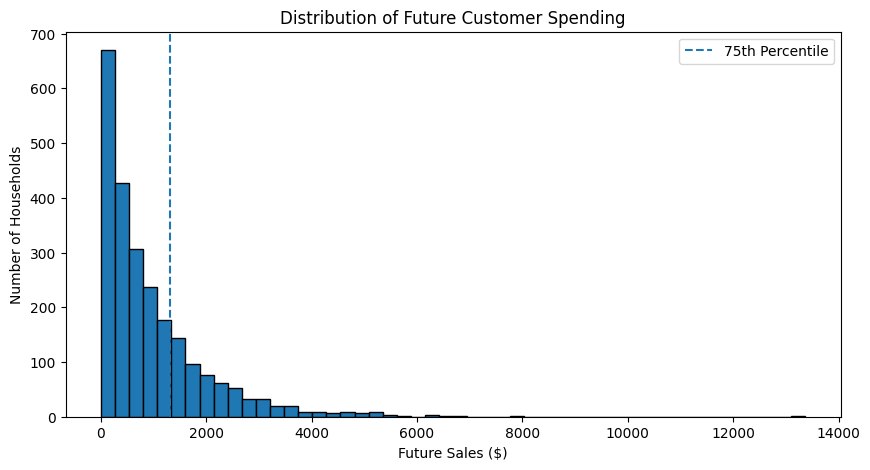

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    future_customer_value["future_sales"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    future_customer_value["future_sales"].quantile(0.75),
    linestyle="--",
    label="75th Percentile"
)

plt.title("Distribution of Future Customer Spending")
plt.xlabel("Future Sales ($)")
plt.ylabel("Number of Households")
plt.legend()

plt.show()

In [21]:
high_value_cutoff = future_customer_value["future_sales"].quantile(0.75)

future_customer_value["high_value"] = (
    future_customer_value["future_sales"] >= high_value_cutoff
).astype(int)

print("High-value cutoff:", round(high_value_cutoff, 2))

future_customer_value["high_value"].value_counts()

High-value cutoff: 1318.73


,count
high_value,
0,1809
1,604


Decision Record 3 — High-Value Customer Definition
Evidence: Future customer spending during Weeks 68–93 was strongly right-skewed. The median future spending was $613.68, while the 75th percentile was $1,318.73. Using the 75th percentile resulted in 604 high-value customers and 1,809 other customers.
Decision: I will define a future high-value customer as a household with at least $1,318.73 in total sales during Weeks 68–93. These customers receive a target value of 1, while all other customers receive a target value of 0.
Logic: The 75th percentile provides a data-driven cutoff that identifies the top 25% of customers by future spending rather than choosing an arbitrary dollar amount.
Alternative and tradeoff: I could use the median as the cutoff, but that would classify about half of the customers as high-value and make the definition less selective.

In [22]:
customer_features = con.execute("""
SELECT
    household_key,

    COUNT(DISTINCT BASKET_ID) AS basket_count,

    ROUND(SUM(SALES_VALUE), 2) AS total_sales,

    ROUND(AVG(SALES_VALUE), 2) AS avg_item_sales,

    COUNT(DISTINCT PRODUCT_ID) AS unique_products,

    COUNT(DISTINCT STORE_ID) AS unique_stores,

    COUNT(DISTINCT WEEK_NO) AS active_weeks,

    ROUND(SUM(QUANTITY), 2) AS total_quantity,

    ROUND(SUM(RETAIL_DISC), 2) AS total_retail_discount,

    ROUND(SUM(COUPON_DISC), 2) AS total_coupon_discount

FROM transaction_data
WHERE WEEK_NO BETWEEN 18 AND 67
GROUP BY household_key
ORDER BY household_key
""").df()

customer_features.head()

,household_key,basket_count,total_sales,avg_item_sales,unique_products,unique_stores,active_weeks,total_quantity,total_retail_discount,total_coupon_discount
0,1,42,2382.53,2.49,450,1,34,1136.0,-413.56,-57.78
1,2,30,1087.36,2.88,317,5,22,453.0,-195.49,-3.50
2,3,38,2335.24,3.01,454,1,28,1392.0,-621.49,-61.19
3,4,24,908.44,4.06,130,5,20,268.0,-74.77,0.00
4,5,24,456.69,3.07,135,1,16,164.0,-66.90,0.00


In [23]:
model_data = customer_features.merge(
    future_customer_value[["household_key", "high_value"]],
    on="household_key",
    how="inner"
)

print("Number of rows:", len(model_data))
print("Unique households:", model_data["household_key"].nunique())
print("Duplicate households:", model_data["household_key"].duplicated().sum())

model_data.head()

Number of rows: 2390
Unique households: 2390
Duplicate households: 0


,household_key,basket_count,total_sales,avg_item_sales,unique_products,unique_stores,active_weeks,total_quantity,total_retail_discount,total_coupon_discount,high_value
0,1,42,2382.53,2.49,450,1,34,1136.0,-413.56,-57.78,0
1,2,30,1087.36,2.88,317,5,22,453.0,-195.49,-3.50,0
2,3,38,2335.24,3.01,454,1,28,1392.0,-621.49,-61.19,0
3,4,24,908.44,4.06,130,5,20,268.0,-74.77,0.00,0
4,5,24,456.69,3.07,135,1,16,164.0,-66.90,0.00,0


In [24]:
print("MISSING VALUES")
print(model_data.isnull().sum())

print("\nTARGET DISTRIBUTION")
print(model_data["high_value"].value_counts())

print("\nTARGET PERCENTAGES")
print(
    model_data["high_value"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFEATURE SUMMARY")
display(
    model_data.drop(columns=["household_key", "high_value"]).describe().T
)

MISSING VALUES
household_key            0
basket_count             0
total_sales              0
avg_item_sales           0
unique_products          0
unique_stores            0
active_weeks             0
total_quantity           0
total_retail_discount    0
total_coupon_discount    0
high_value               0
dtype: int64

TARGET DISTRIBUTION
high_value
0    1787
1     603
Name: count, dtype: int64

TARGET PERCENTAGES
high_value
0    74.77
1    25.23
Name: proportion, dtype: float64

FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
basket_count,2390.0,61.654393,68.725345,1.00,20.00,42.000,79.0000,899.00
total_sales,2390.0,1771.046615,1897.758397,2.63,469.32,1162.540,2403.5525,20363.54
avg_item_sales,2390.0,3.174314,1.290901,0.92,2.54,2.980,3.5100,24.68
unique_products,2390.0,344.915900,287.661058,1.00,126.00,273.500,493.5000,2199.00
unique_stores,2390.0,4.080753,2.645784,1.00,2.00,3.000,5.0000,19.00
active_weeks,2390.0,27.226360,14.258901,1.00,15.00,27.000,40.0000,50.00
total_quantity,2390.0,58248.153138,145616.377987,2.00,312.00,1757.000,44316.5000,2578275.00
total_retail_discount,2390.0,-308.556314,321.855853,-2741.37,-425.85,-208.435,-82.9950,0.00
total_coupon_discount,2390.0,-9.110862,22.961286,-275.36,-7.15,-1.550,0.0000,0.00


In [25]:
feature_columns = [
    "basket_count",
    "total_sales",
    "avg_item_sales",
    "unique_products",
    "unique_stores",
    "active_weeks",
    "total_quantity",
    "total_retail_discount",
    "total_coupon_discount"
]

X = model_data[feature_columns]
y = model_data["high_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Test customers:", len(X_test))

print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target percentages:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training customers: 1673
Test customers: 717

Training target percentages:
high_value
0    74.78
1    25.22
Name: proportion, dtype: float64

Test target percentages:
high_value
0    74.76
1    25.24
Name: proportion, dtype: float64


In [26]:
depth_results = []

for depth in [2, 3, 5, 8]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    train_accuracy = accuracy_score(y_train, train_predictions)

    depth_results.append({
        "max_depth": depth,
        "training_accuracy": round(train_accuracy, 4)
    })

depth_results_df = pd.DataFrame(depth_results)

depth_results_df

,max_depth,training_accuracy
0,2,0.8745
1,3,0.8787
2,5,0.8960
3,8,0.9372


In [27]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

validation_results = []

for depth in [2, 3, 5, 8]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_sub, y_train_sub)

    train_pred = model.predict(X_train_sub)
    val_pred = model.predict(X_val)

    validation_results.append({
        "max_depth": depth,
        "training_accuracy": round(
            accuracy_score(y_train_sub, train_pred), 4
        ),
        "validation_accuracy": round(
            accuracy_score(y_val, val_pred), 4
        )
    })

validation_results_df = pd.DataFrame(validation_results)

validation_results_df

,max_depth,training_accuracy,validation_accuracy
0,2,0.8707,0.8896
1,3,0.8759,0.8896
2,5,0.8946,0.8657
3,8,0.9402,0.8507


Decision Record 4 — Decision Tree Complexity
Evidence: I compared decision trees with maximum depths of 2, 3, 5, and 8 using a validation set. Depths 2 and 3 both achieved the highest validation accuracy of 88.96%. Depth 5 achieved 86.57%, while depth 8 achieved 86.07%. Although deeper trees had higher training accuracy, their validation performance decreased.
Decision: I selected a maximum tree depth of 2.
Logic: Depth 2 achieved the highest validation accuracy while remaining simpler and easier to interpret than depth 3. The decline in validation accuracy for depths 5 and 8 suggests that the more complex trees were beginning to overfit the training data.
Alternative and tradeoff: Depth 3 achieved the same validation accuracy and could capture additional customer patterns, but it adds complexity without improving validation performance.

In [28]:
final_model = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Train the final model using the full training set
final_model.fit(X_train, y_train)

# Predict the untouched test set
test_predictions = final_model.predict(X_test)

# Calculate final test accuracy
test_accuracy = accuracy_score(y_test, test_predictions)

print("Final Test Accuracy:", round(test_accuracy, 4))
print("Final Test Accuracy (%):", round(test_accuracy * 100, 2))

Final Test Accuracy: 0.855
Final Test Accuracy (%): 85.5


Confusion Matrix:
[[470  66]
 [ 38 143]]


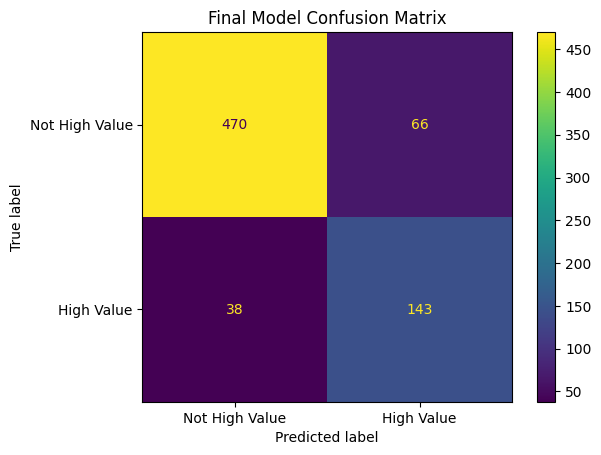

In [29]:
# Create confusion matrix for the final model
cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not High Value", "High Value"]
)

disp.plot()
plt.title("Final Model Confusion Matrix")
plt.show()

In [30]:
# Get feature importance from the final decision tree
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": final_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
1,total_sales,1.0
0,basket_count,0.0
2,avg_item_sales,0.0
3,unique_products,0.0
4,unique_stores,0.0
5,active_weeks,0.0
6,total_quantity,0.0
7,total_retail_discount,0.0
8,total_coupon_discount,0.0


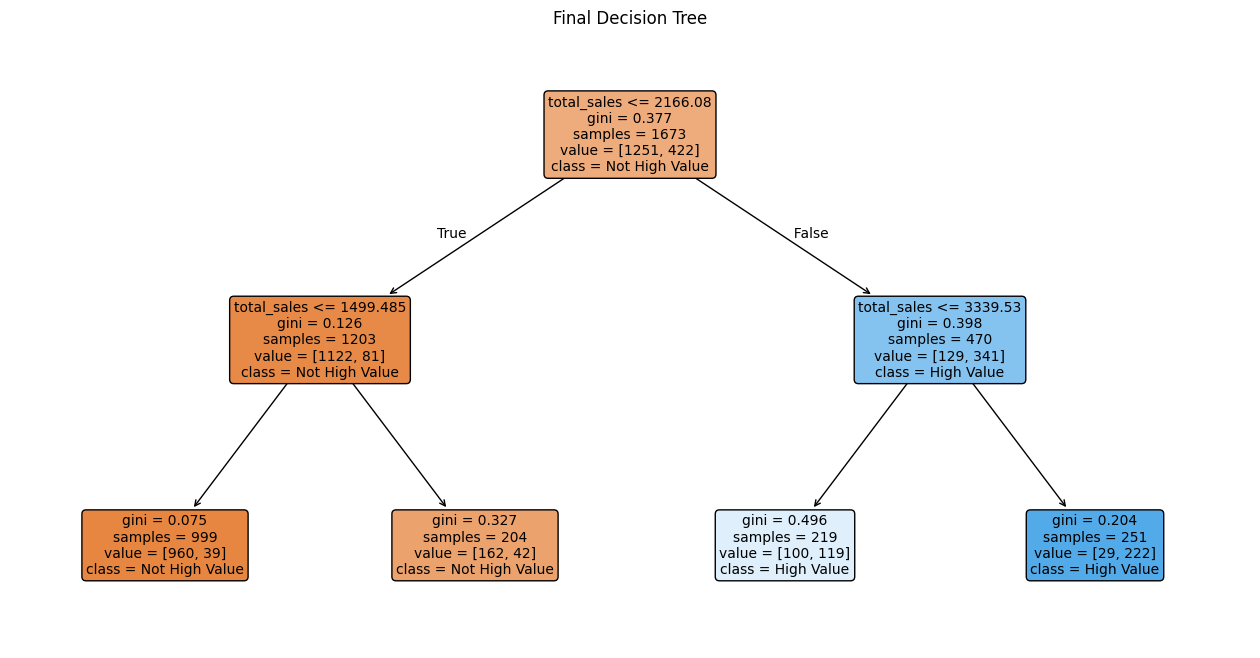

In [31]:
plt.figure(figsize=(16, 8))

plot_tree(
    final_model,
    feature_names=feature_columns,
    class_names=["Not High Value", "High Value"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Final Decision Tree")
plt.show()

Decision Record 5 – Final Model Interpretation: The final decision tree achieved 85.5% test accuracy. The confusion matrix showed that the model correctly classified 470 not-high-value customers and 143 high-value customers, while misclassifying 66 not-high-value customers and 38 high-value customers. Feature importance analysis showed that total_sales had an importance of 1.0, while all other predictors had an importance of 0.0. The decision tree confirms that the model makes its predictions entirely from total sales, using splits around $1,499.49, $2,166.08, and $3,339.53. This makes the model simple and interpretable, but it also suggests that customer spending during the observation period dominates the other available behavioral features.

In [32]:
from sklearn.metrics import classification_report

print("Final Model Classification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Not High Value", "High Value"]
    )
)

Final Model Classification Report:
                precision    recall  f1-score   support

Not High Value       0.93      0.88      0.90       536
    High Value       0.68      0.79      0.73       181

      accuracy                           0.85       717
     macro avg       0.80      0.83      0.82       717
  weighted avg       0.86      0.85      0.86       717



Final Model Evaluation: The final decision tree achieved an overall test accuracy of 85%. For high-value customers, the model achieved a precision of 0.68, recall of 0.79, and F1-score of 0.73. This means the model identified approximately 79% of the actual high-value customers, although some customers predicted as high-value were actually not high-value. For not-high-value customers, the model performed more strongly, with precision of 0.93, recall of 0.88, and F1-score of 0.90. Overall, the model provides a relatively simple and interpretable method for identifying customers who may have high future value.

Business Recommendation: The model can be used to help identify customers who are more likely to become high-value customers in the future. Because the model captures 79% of actual high-value customers, it could help a retailer prioritize customers for targeted marketing, loyalty offers, or promotional campaigns. Total sales during the observation period was the strongest predictor of future customer value. However, the model should be used as a decision-support tool rather than as a perfect prediction system because some customers are incorrectly classified as high-value.

Conclusion
This project used historical transaction data to predict which households are likely to become high-value customers in a future period. I first explored the transaction data and selected weeks 18–67 as the observation period and weeks 68–93 as the outcome period. Customer-level behavioral features were then created from the observation period, including basket count, total sales, average item sales, unique products, unique stores, active weeks, quantity, and discounts.
A decision tree classifier was tested at several levels of complexity. Based on validation performance, a maximum depth of 2 was selected for the final model. The final model achieved 85.5% test accuracy and identified 79% of actual high-value customers.
The model relied entirely on total sales as its predictive feature, making the final decision tree simple and easy to interpret. The results suggest that past customer spending can provide useful information for identifying customers with potentially high future value. However, the model is not perfect and should be used as a decision-support tool rather than as the sole basis for business decisions.
Overall, this analysis demonstrates how transaction data can be transformed into customer-level features and used with a simple machine-learning model to support customer targeting and marketing decisions.